# FSRE-AdaTSK: feature selection, rule extraction and fine-tuning

This notebook follows, one step at a time, the classifier of

> G. Xue, Q. Chang, J. Wang, K. Zhang and N. R. Pal, "An adaptive neuro-fuzzy system with
> integrated feature selection and rule extraction for high-dimensional classification
> problems", *IEEE Transactions on Fuzzy Systems*, vol. 31, no. 7, pp. 2167-2181, 2023.

on Wine, one of the datasets of the article. FSRE-AdaTSK trains in three phases: gates
select the features, then gates extract the rules from an enhanced rule base built on the
selected features, and the remaining system is fine-tuned. The notebook is a short
version of the script `examples/reproductions/fsre_adatsk_2022.py`, which runs eight
datasets with ten folds repeated five times; here one repetition on one dataset runs in
a few minutes.

1. settings and reproducibility;
2. the data;
3. the three phases on one fold;
4. why the scale of the inputs matters;
5. what the fitted model looks like;
6. ten folds, next to the article.

## 1. Settings and reproducibility

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import load_wine
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, StandardScaler

import highfis
from highfis import FSREADATSKClassifier

In [2]:
SEED = 0
FOLDS = 10
THREADS = 1

# The settings of the article: ten fuzzy sets per feature in the feature-selection phase,
# five in the rule-extraction phase, no normalization of the consequent inputs. The number
# of iterations of the rule-extraction phase is not stated; 600 are used.
SETTINGS = dict(fs_n_mfs=10, re_n_mfs=5, re_epochs=600, consequent_batch_norm=False)

# Table IV of the article, Wine: accuracy in percent, selected features, extracted rules.
ARTICLE = (97.3, 6.3, 6.3)

torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)
highfis.set_mf_cache_enabled(False)

## 2. The data

Wine has 178 samples of three cultivars, described by 13 chemical measurements.

In [3]:
wine = load_wine()
features, labels, feature_names = wine.data.astype(np.float32), wine.target, wine.feature_names

print(f"{features.shape[0]} samples, {features.shape[1]} features, {labels.max() + 1} classes")

178 samples, 13 features, 3 classes


The first of ten folds is followed in detail. The article does not state how the inputs
are scaled; here they are standardized with the mean and the standard deviation of the
training part. Section 4 shows what this choice changes.

In [4]:
folds = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
train, test = next(folds.split(features, labels))
y_train, y_test = labels[train], labels[test]

scaler = StandardScaler().fit(features[train])
x_train, x_test = scaler.transform(features[train]), scaler.transform(features[test])

print(f"training: {len(x_train)} samples, test: {len(x_test)} samples")

training: 160 samples, test: 18 samples


## 3. The three phases on one fold

1. **Feature selection.** Ten fuzzy sets per feature and ten rules. One gate per feature,
   almost closed at the start, is trained with the system; the features whose gates open
   are kept.
2. **Rule extraction.** Five fuzzy sets on each selected feature, and an enhanced rule
   base of $(2D' + 1) \times 5$ rules for $D'$ selected features. One gate per rule is
   trained; the rules whose gates open are kept.
3. **Fine-tuning** of what remains, without gates.

In [5]:
model = FSREADATSKClassifier(random_state=SEED, **SETTINGS).fit(x_train, y_train)

n_selected = len(model.selected_features_)
print(f"selected features: {n_selected} of {x_train.shape[1]}")
print(f"candidate rules in the rule-extraction phase: {(2 * n_selected + 1) * 5}")
print(f"extracted rules: {model.model_.n_rules}")
print(f"test accuracy: {100 * model.score(x_test, y_test):.1f}%")
print([feature_names[d] for d in model.selected_features_])

selected features: 9 of 13
candidate rules in the rule-extraction phase: 95
extracted rules: 5
test accuracy: 100.0%
['alcohol', 'ash', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


The training loss of the three phases, one after the other. The rule-extraction phase starts again from consequents at zero:

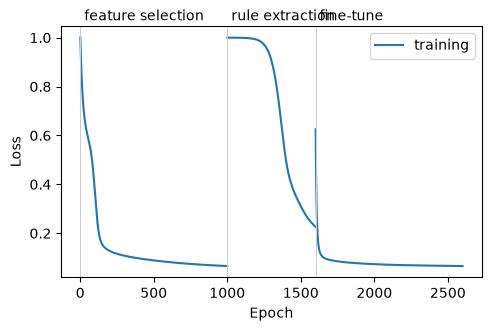

In [6]:
model.plot_history()
plt.show()

The gates of the selected features, at the end of the feature-selection phase, and of the
extracted rules, at the end of the rule-extraction phase, with the thresholds they
passed. The features are numbered from one, in the order of the columns of the data:

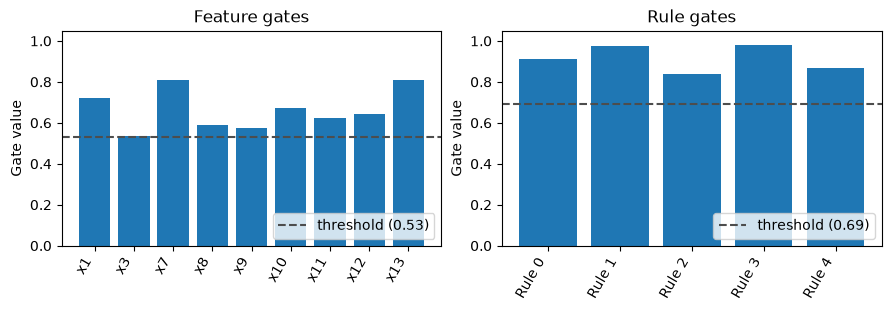

In [7]:
model.plot_gates()
plt.show()

## 4. Why the scale of the inputs matters

The membership function of the article is $e^{-(x - m)^2}$, with no spread. The distance
between the centres of two neighbouring fuzzy sets therefore depends on the scale of the
feature. With five sets:

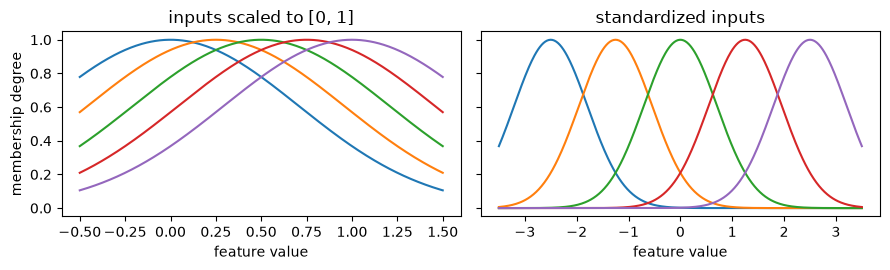

In [8]:
x = np.linspace(-0.5, 1.5, 400)
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)

for centre in np.linspace(0, 1, 5):
    axes[0].plot(x, np.exp(-((x - centre) ** 2)))
axes[0].set_title("inputs scaled to [0, 1]")
axes[0].set_xlabel("feature value")
axes[0].set_ylabel("membership degree")

z = np.linspace(-3.5, 3.5, 400)
for centre in np.linspace(-2.5, 2.5, 5):
    axes[1].plot(z, np.exp(-((z - centre) ** 2)))
axes[1].set_title("standardized inputs")
axes[1].set_xlabel("feature value")
plt.tight_layout()
plt.show()

On [0, 1] the five sets almost coincide, the rules of the enhanced rule base fire alike,
and their gates open together: many rules pass the threshold. The same fold with the
inputs scaled to [0, 1]:

In [9]:
unit = MinMaxScaler().fit(features[train])
on_unit = FSREADATSKClassifier(random_state=SEED, **SETTINGS).fit(unit.transform(features[train]), y_train)

print(f"{'inputs':14s} {'features':>9s} {'rules':>6s} {'test accuracy':>14s}")
print(
    f"{'[0, 1]':14s} {len(on_unit.selected_features_):9d} {on_unit.model_.n_rules:6d} "
    f"{100 * on_unit.score(unit.transform(features[test]), y_test):13.1f}%"
)
print(f"{'standardized':14s} {n_selected:9d} {model.model_.n_rules:6d} {100 * model.score(x_test, y_test):13.1f}%")

inputs          features  rules  test accuracy
[0, 1]                 6     20         100.0%
standardized           9      5         100.0%


## 5. What the fitted model looks like

The model on standardized inputs. Its confusion matrix on the 18 test samples, with the
margin of each decision:

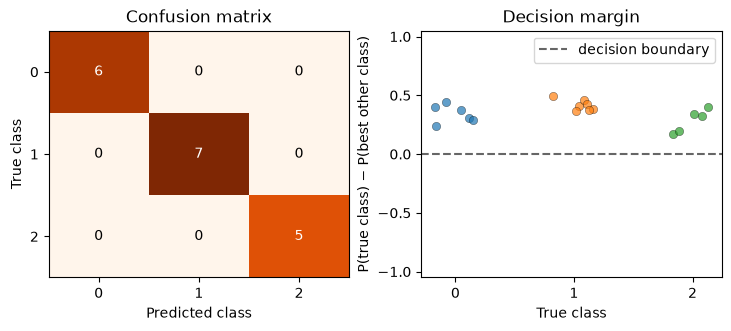

In [10]:
model.plot_diagnostics(x_test, y_test)
plt.show()

How the extracted rules share the samples of each class:

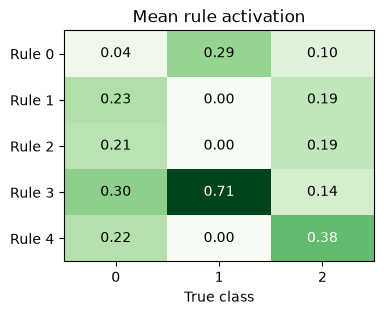

In [11]:
fig, ax = plt.subplots(figsize=(4, 3))
model.plot_rule_activation(x_test, y_test, ax=ax)
plt.show()

The fuzzy sets of four of the selected features, after fine-tuning:

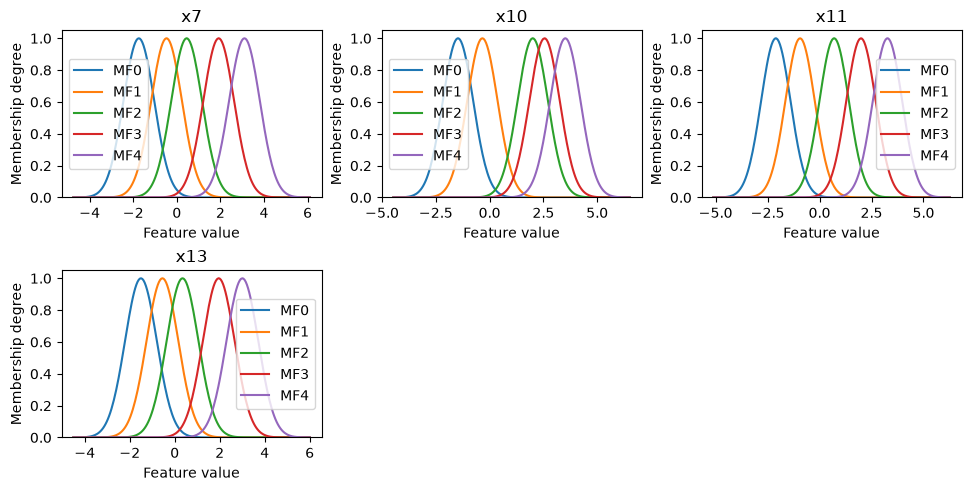

In [12]:
model.plot_memberships(max_features=4)
plt.show()

The rules as sentences, with the three features that weigh most in each consequent:

In [13]:
print(model.rules_as_text(top_features=3))

Rule 0: IF x7 is low AND x10 is low AND x11 is low AND ... (6 more)
        THEN 0: 0.09 + 0.09 * x7 + 0.07 * x13 + 0.03 * x3 + ...
             1: 0.54 - 0.22 * x3 + 0.22 * x11 + 0.17 * x7 + ...
             2: 0.25 - 0.32 * x7 - 0.20 * x11 + 0.19 * x3 + ...
Rule 1: IF x7 is medium AND x10 is medium AND x11 is medium AND ... (6 more)
        THEN 0: 0.41 + 0.22 * x12 + 0.19 * x7 + 0.18 * x3 + ...
             1: 0.12 + 0.16 * x11 - 0.16 * x3 - 0.08 * x1 + ...
             2: 0.29 - 0.24 * x7 + 0.16 * x8 - 0.15 * x11 + ...
Rule 2: IF x7 is medium AND x10 is medium AND x11 is medium AND ... (6 more)
        THEN 0: 0.27 + 0.22 * x1 - 0.21 * x10 + 0.13 * x11 + ...
             1: 0.05 + 0.22 * x7 + 0.16 * x10 - 0.13 * x1 + ...
             2: 0.24 - 0.18 * x11 - 0.15 * x7 + 0.15 * x10 + ...
Rule 3: IF x7 is medium AND x10 is low AND x11 is medium AND ... (6 more)
        THEN 0: 0.58 + 0.31 * x13 + 0.15 * x1 + 0.14 * x10 + ...
             1: 0.44 - 0.29 * x13 - 0.20 * x10 - 0.15 * x1 + 

A summary of the model and of its training, in one call:

In [14]:
print(model.summary())

FSREADATSKClassifier
  task               classification, 3 classes
  features           13 seen in fit, 9 used by the model
  rules              5 (rule base: coco)
  fuzzy sets         5 per feature, ADATSKGaussianMF
  firing strength    AdaSoftminRuleLayer
  defuzzifier        SoftmaxLogDefuzzifier
  consequents        GatedClassificationConsequentLayer
  parameters         209 trainable (45 antecedent, 164 consequent)
Training (full batch)
  phase              epochs  rate  loss first -> last  accuracy
  feature selection    1000  0.05    1.0000 -> 0.0657    1.0000
  rule extraction       600  0.05    1.0000 -> 0.2262    0.9625
  fine-tuning          1000  0.05    0.6252 -> 0.0658    0.9937


How the rules produce the prediction of the first test sample. The output is the sum of
what each rule contributes, and the predicted class is the one with the largest value:

In [15]:
print(model.explain(x_test[0]))

Prediction: 0
Output, the sum of the contributions of the 5 rules: 0: +1.05, 1: -0.06, 2: +0.03
Rule 1, weight 0.25: contributes 0: +0.33, 1: -0.05, 2: +0.01
    IF x7 is medium AND x10 is medium AND x11 is medium AND ... (6 more)
Rule 2, weight 0.25: contributes 0: +0.16, 1: +0.08, 2: -0.01
    IF x7 is medium AND x10 is medium AND x11 is medium AND ... (6 more)
Rule 3, weight 0.25: contributes 0: +0.41, 1: -0.14, 2: +0.02
    IF x7 is medium AND x10 is low AND x11 is medium AND ... (6 more)
2 other rules, weight 0.25 in all: contribute 0: +0.15, 1: +0.05, 2: +0.01


How well the rules cover the samples: for each sample, the mean membership degree in its
best-matching rule. A test sample with a coverage well below the training samples would
lie outside the region the rules were built on:

In [16]:
inside, outside = model.coverage(x_train), model.coverage(x_test)
print(f"training part: min {inside.min():.2f}, median {np.median(inside):.2f}")
print(f"test part:     min {outside.min():.2f}, median {np.median(outside):.2f}")

training part: min 0.33, median 0.62
test part:     min 0.35, median 0.57


## 6. Ten folds, next to the article

In [17]:
runs, selections = [], []

for train, test in StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED).split(features, labels):
    scaler = StandardScaler().fit(features[train])
    a_train, a_test = scaler.transform(features[train]), scaler.transform(features[test])

    fitted = FSREADATSKClassifier(random_state=SEED, **SETTINGS).fit(a_train, labels[train])
    runs.append((100 * fitted.score(a_test, labels[test]), len(fitted.selected_features_), fitted.model_.n_rules))
    selections.append(fitted.selected_features_)

runs = np.asarray(runs)
print(f"{'':10s} {'accuracy':>9s} {'features':>9s} {'rules':>6s}")
print(f"{'article':10s} {ARTICLE[0]:9.1f} {ARTICLE[1]:9.1f} {ARTICLE[2]:6.1f}")
print(f"{'highFIS':10s} {runs[:, 0].mean():9.1f} {runs[:, 1].mean():9.1f} {runs[:, 2].mean():6.1f}")

            accuracy  features  rules
article         97.3       6.3    6.3
highFIS         95.6       8.1    6.6


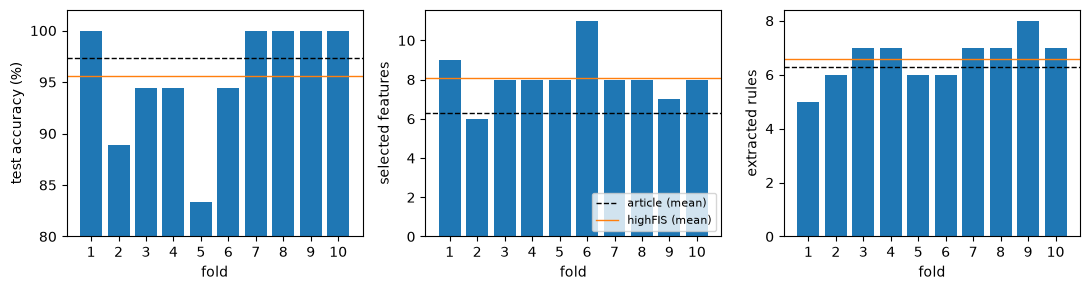

In [18]:
LOWER = 80

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
folds_axis = np.arange(1, FOLDS + 1)
for ax, column, label, reported in zip(axes, range(3), ["test accuracy (%)", "selected features", "extracted rules"], ARTICLE):
    ax.bar(folds_axis, runs[:, column])
    ax.axhline(reported, color="black", linestyle="--", linewidth=1, label="article (mean)")
    ax.axhline(runs[:, column].mean(), color="tab:orange", linewidth=1, label="highFIS (mean)")
    ax.set_xticks(folds_axis)
    ax.set_xlabel("fold")
    ax.set_ylabel(label)
axes[0].set_ylim(LOWER, 102)
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

How often each feature is selected over the ten folds:

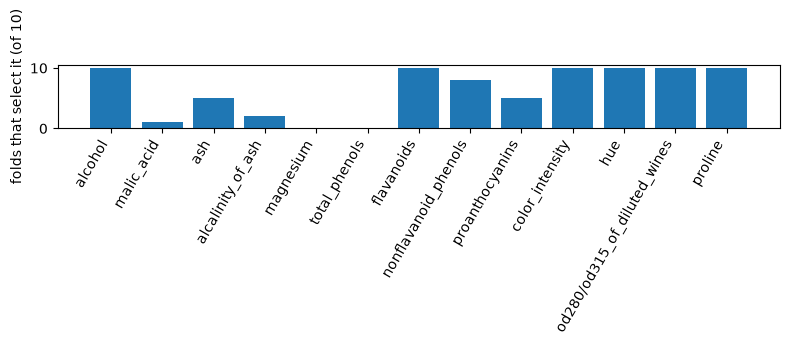

In [19]:
frequency = np.bincount(np.concatenate(selections), minlength=features.shape[1])

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(len(frequency)), frequency)
ax.set_xticks(range(len(frequency)), feature_names, rotation=60, ha="right")
ax.set_ylabel(f"folds that select it (of {FOLDS})")
plt.tight_layout()
plt.show()

The script repeats the ten folds five times, as the article does, and runs seven more
datasets; over the 50 runs Wine gives 96.18% with 8.22 features and 6.80 rules.